# Notebook 07 — Predictive Analytics and Baselines

**Purpose:** Establish the ML architecture (train/test split, CV, evaluation framework) and train baseline models (Logistic Regression, Decision Tree).

**Inputs:** Engineered dataset, train/test indices, selected features, preprocessing pipeline

**Outputs:**
- Baseline model artifacts (`models/base_models/`)
- Baseline metrics (`results/metrics/07_baseline_metrics.csv`)
- OOF predictions for baselines


In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_predict

from src.config import *
from src.data_utils import (
    ALL_ORIGINAL_FEATURES, ENGINEERED_FEATURES, engineer_features,
    build_preprocessing_pipeline, get_cv_splitter, save_artifact, load_artifact,
    CONTINUOUS_FEATURES,
)
from src.evaluation import compute_all_metrics, metrics_to_dataframe, print_confusion_matrix
from src.plotting import plot_confusion_matrix, plot_roc_curves, plot_pr_curves, save_figure

seed_everything()

# Load data
df = pd.read_csv(os.path.join(DATA_PROCESSED, "df1_engineered.csv"))
train_idx = np.load(os.path.join(DATA_PROCESSED, "train_indices.npy"))
test_idx = np.load(os.path.join(DATA_PROCESSED, "test_indices.npy"))

FEATURES = load_artifact(os.path.join(MODELS_PREPROC, "selected_features.joblib"))

X_train = df.loc[train_idx, FEATURES].copy()
y_train = df.loc[train_idx, TARGET_COL].copy()
X_test = df.loc[test_idx, FEATURES].copy()
y_test = df.loc[test_idx, TARGET_COL].copy()

print(f"Features: {len(FEATURES)}")
print(f"Training: {X_train.shape[0]:,}  |  Test: {X_test.shape[0]:,}")
print(f"Test set is LOCKED — used only for final evaluation.")


Features: 29
Training: 202,944  |  Test: 50,736
Test set is LOCKED — used only for final evaluation.


## 7.1 Preprocessing for Baselines

In [2]:
# Build and fit preprocessing on training data
preprocessor = build_preprocessing_pipeline(FEATURES)
preprocessor.fit(X_train)

X_train_pp = preprocessor.transform(X_train)
X_test_pp = preprocessor.transform(X_test)
feature_names_out = list(preprocessor.get_feature_names_out())

print(f"Preprocessed training shape: {X_train_pp.shape}")
print(f"Preprocessed test shape: {X_test_pp.shape}")


Preprocessed training shape: (202944, 29)
Preprocessed test shape: (50736, 29)


## 7.2 Cross-Validation Setup

In [3]:
cv = get_cv_splitter()
print(f"CV strategy: {N_FOLDS}-fold StratifiedKFold")
print(f"Random seed: {RANDOM_SEED}")


CV strategy: 5-fold StratifiedKFold
Random seed: 42


## 7.3 Baseline 1 — Logistic Regression

In [4]:
# Logistic Regression with class weights
lr = LogisticRegression(
    max_iter=2000, random_state=RANDOM_SEED,
    class_weight="balanced", 
    solver="lbfgs", C=1.0, n_jobs=-1,
)

# OOF predictions
t0 = time.time()
lr_oof_prob = cross_val_predict(lr, X_train_pp, y_train, cv=cv, method="predict_proba", n_jobs=-1)
lr_oof_pred = lr_oof_prob.argmax(axis=1)
lr_cv_time = time.time() - t0

# Train on full training set
lr.fit(X_train_pp, y_train)
lr_test_prob = lr.predict_proba(X_test_pp)
lr_test_pred = lr.predict(X_test_pp).flatten()

print(f"Logistic Regression trained in {lr_cv_time:.1f}s (CV)")

# OOF metrics
lr_oof_metrics = compute_all_metrics(y_train, lr_oof_pred, lr_oof_prob, "LR_OOF")
print(f"  OOF Macro F1: {lr_oof_metrics['Macro_F1']:.4f}")
print(f"  OOF Balanced Acc: {lr_oof_metrics['Balanced_Accuracy']:.4f}")

# Test metrics (LOCKED)
lr_test_metrics = compute_all_metrics(y_test, lr_test_pred, lr_test_prob, "LR_Test")


Logistic Regression trained in 13.0s (CV)


  OOF Macro F1: 0.4275
  OOF Balanced Acc: 0.5202


Logistic Regression — OOF Confusion Matrix:
Predicted    No Diabetes  Prediabetes  Diabetes
Actual                                         
No Diabetes       112595        31117     27250
Prediabetes         1031         1177      1497
Diabetes            4745         7009     16523


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\07_lr_confusion.png


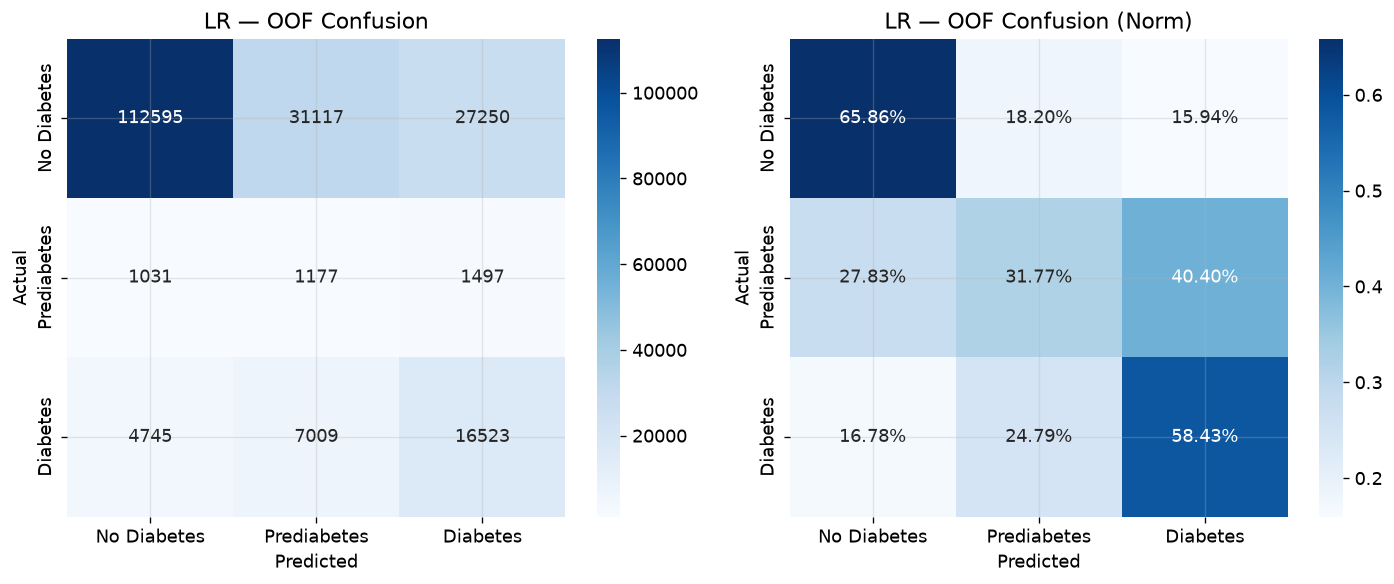

In [5]:
# Confusion matrix
cm_df = print_confusion_matrix(y_train, lr_oof_pred)
print("Logistic Regression — OOF Confusion Matrix:")
print(cm_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_confusion_matrix(y_train, lr_oof_pred, title="LR — OOF Confusion", ax=axes[0])
plot_confusion_matrix(y_train, lr_oof_pred, title="LR — OOF Confusion (Norm)", ax=axes[1], normalize=True)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "07_lr_confusion.png"))
plt.show()


## 7.4 Baseline 2 — Decision Tree

In [6]:
dt = DecisionTreeClassifier(
    random_state=RANDOM_SEED, class_weight="balanced",
    max_depth=10,
)

t0 = time.time()
dt_oof_prob = cross_val_predict(dt, X_train_pp, y_train, cv=cv, method="predict_proba", n_jobs=-1)
dt_oof_pred = dt_oof_prob.argmax(axis=1)
dt_cv_time = time.time() - t0

dt.fit(X_train_pp, y_train)
dt_test_prob = dt.predict_proba(X_test_pp)
dt_test_pred = dt.predict(X_test_pp).flatten()

print(f"Decision Tree trained in {dt_cv_time:.1f}s (CV)")

dt_oof_metrics = compute_all_metrics(y_train, dt_oof_pred, dt_oof_prob, "DT_OOF")
print(f"  OOF Macro F1: {dt_oof_metrics['Macro_F1']:.4f}")
print(f"  OOF Balanced Acc: {dt_oof_metrics['Balanced_Accuracy']:.4f}")

dt_test_metrics = compute_all_metrics(y_test, dt_test_pred, dt_test_prob, "DT_Test")


Decision Tree trained in 2.7s (CV)


  OOF Macro F1: 0.3938
  OOF Balanced Acc: 0.4924


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\07_dt_confusion.png


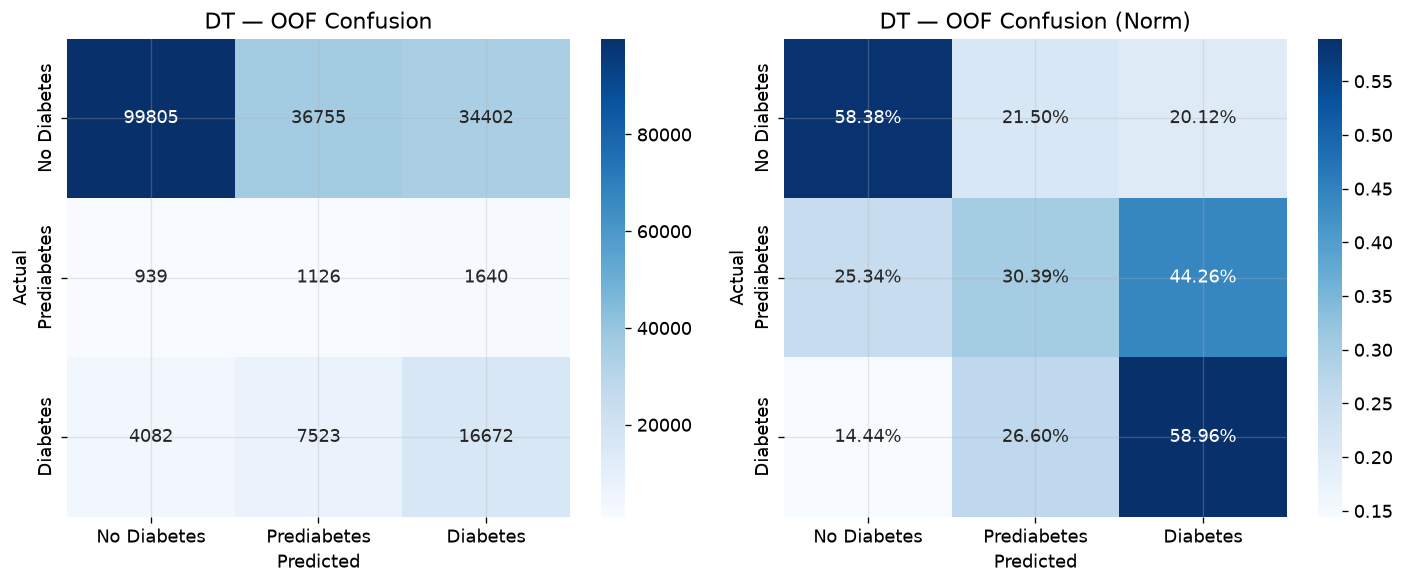

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_confusion_matrix(y_train, dt_oof_pred, title="DT — OOF Confusion", ax=axes[0])
plot_confusion_matrix(y_train, dt_oof_pred, title="DT — OOF Confusion (Norm)", ax=axes[1], normalize=True)
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "07_dt_confusion.png"))
plt.show()


## 7.5 Baseline Comparison

In [8]:
# Compare baselines
baseline_metrics = metrics_to_dataframe([lr_oof_metrics, dt_oof_metrics])
print("\nBaseline OOF Comparison:")
print(baseline_metrics.round(4).to_string())

baseline_metrics.to_csv(os.path.join(RESULTS_METRICS, "07_baseline_metrics.csv"))

# Save models
save_artifact(lr, os.path.join(MODELS_BASE, "logistic_regression.joblib"))
save_artifact(dt, os.path.join(MODELS_BASE, "decision_tree.joblib"))

# Save OOF predictions
oof_data = pd.DataFrame({
    "index": train_idx,
    "y_true": y_train.values,
    "lr_pred": lr_oof_pred,
    "dt_pred": dt_oof_pred,
})
for c in range(N_CLASSES):
    oof_data[f"lr_prob_{c}"] = lr_oof_prob[:, c]
    oof_data[f"dt_prob_{c}"] = dt_oof_prob[:, c]
oof_data.to_csv(os.path.join(RESULTS_METRICS, "07_baseline_oof.csv"), index=False)
print("\n✓ Baseline OOF predictions saved.")



Baseline OOF Comparison:
        Accuracy  Macro_Precision  Macro_Recall  Macro_F1  Balanced_Accuracy     MCC  Precision_Class0  Recall_Class0  F1_Class0  Precision_Class1  Recall_Class1  F1_Class1  Precision_Class2  Recall_Class2  F1_Class2  ROC_AUC_OVR  PR_AUC  Log_Loss  Brier_Score
Model                                                                                                                                                                                                                                                               
LR_OOF    0.6420           0.4487        0.5202    0.4275             0.5202  0.2949            0.9512         0.6586     0.7783            0.0299         0.3177     0.0547            0.3650         0.5843     0.4493       0.7734  0.4662    0.8802       0.1628
DT_OOF    0.5795           0.4311        0.4924    0.3938             0.4924  0.2550            0.9521         0.5838     0.7238            0.0248         0.3039     0.0459            0.3163 


✓ Baseline OOF predictions saved.


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\07_baseline_roc.png


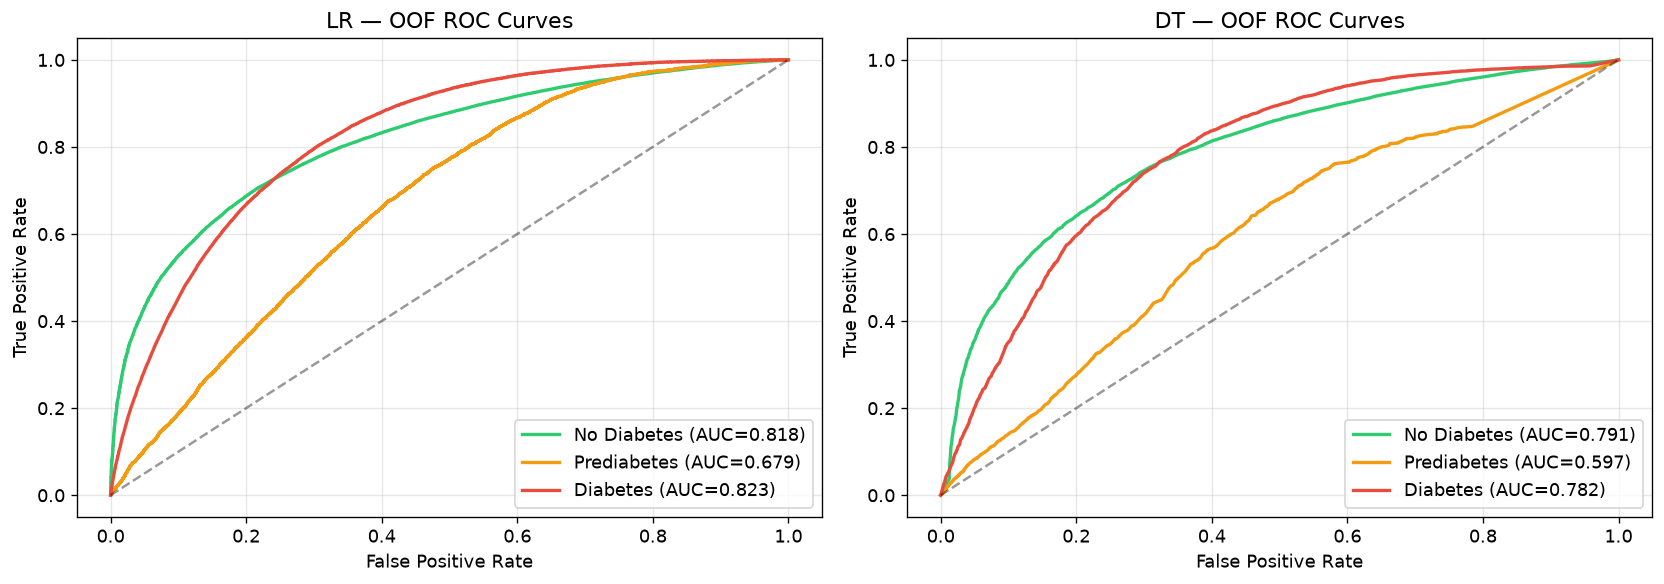

In [9]:
# ROC and PR curves for baselines
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_roc_curves(y_train, lr_oof_prob, title="LR — OOF ROC Curves", ax=axes[0])
plot_roc_curves(y_train, dt_oof_prob, title="DT — OOF ROC Curves", ax=axes[1])
plt.tight_layout()
save_figure(fig, os.path.join(RESULTS_FIGURES, "07_baseline_roc.png"))
plt.show()


## 7.6 Conclusion

**Baseline results:**

1. **Logistic Regression** provides a reasonable baseline for a linear model, with class weights helping to address imbalance.
2. **Decision Tree** captures non-linear patterns but may overfit or underfit depending on depth.
3. Both baselines struggle with the **Prediabetes class** (Class 1) due to severe imbalance and feature overlap.
4. These baselines establish the performance floor that more complex models must improve upon.

**Next:** Notebook 08 — Existing Models (RF, SVM, XGBoost, LightGBM, CatBoost)
